# 04 Bivariate EDA

This notebook is a starting point for bivariate exploratory data analysis on the cleaned ElectraHub dataset.

Suggested flow:
- load the cleaned dataset
- inspect relationships between numeric variables
- compare Sales across categorical groups
- note key pairwise insights

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd

dataset_path = Path("../data/processed/ElectraHub_Data_cleaned.csv")
df = pd.read_csv(dataset_path)

print(f"Dataset path: {dataset_path}")
print(f"Rows loaded: {len(df)}")
print(f"Columns loaded: {len(df.columns)}")

Dataset path: ../data/processed/ElectraHub_Data_cleaned.csv
Rows loaded: 3000
Columns loaded: 16


In [3]:
df.head()

  Region Product_Category  ... Popularity     Sales
0  South           Tablet  ...   Moderate  12265.79
1   West           Tablet  ...       High  20426.45
2   West           Mobile  ...       High  29827.18
3   East           Tablet  ...   Moderate  28211.95
4  North           Mobile  ...       High  29794.80

[5 rows x 16 columns]

In [4]:
numeric_columns = df.select_dtypes(include="number").columns.tolist()
categorical_columns = df.select_dtypes(exclude="number").columns.tolist()

print("Numeric columns:", numeric_columns)
print("Categorical columns:", categorical_columns)

Numeric columns: ['Product_Age_Months', 'Product_Price', 'Competitor_Price_Index', 'Advertising_Expenditure', 'Discount_Percentage', 'Campaign_Engagement_Score', 'Inventory_Level', 'Num_Reviews', 'Avg_Customer_Rating', 'Return_Rate', 'Length_Product_Description', 'Sales']
Categorical columns: ['Region', 'Product_Category', 'Campaign_Type', 'Popularity']


## Numeric Relationships

Use this section to inspect correlations and pairwise relationships between numeric variables.

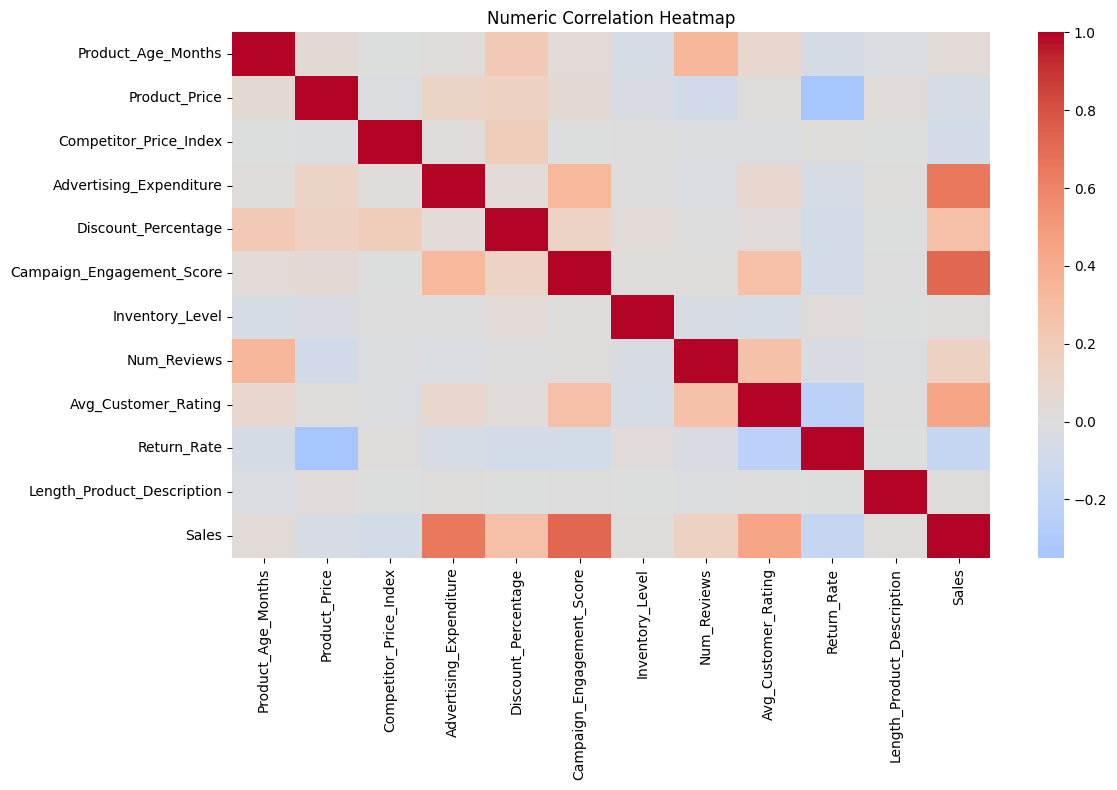

In [6]:
plt.figure(figsize=(12, 8))
sns.heatmap(df[numeric_columns].corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Numeric Correlation Heatmap")
plt.tight_layout()
plt.show()

### Advertising Expenditure vs Sales

The scatter plot below shows the raw relationship between Advertising_Expenditure and Sales.

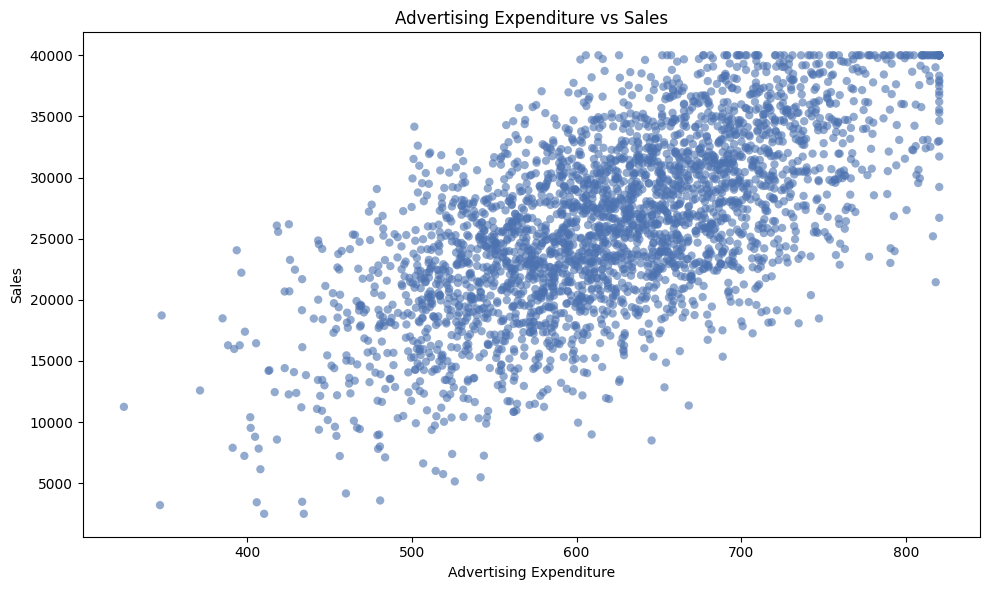

In [8]:
plt.figure(figsize=(10, 6))
plt.scatter(df["Advertising_Expenditure"], df["Sales"], alpha=0.6, color="#4C72B0", edgecolors="none")
plt.title("Advertising Expenditure vs Sales")
plt.xlabel("Advertising Expenditure")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

## Categorical Relationships

Use this section to compare numeric outcomes across categorical groups.

### Sales by Popularity

The box plot below shows Sales grouped by Popularity, ordered from Very Low to Very High.

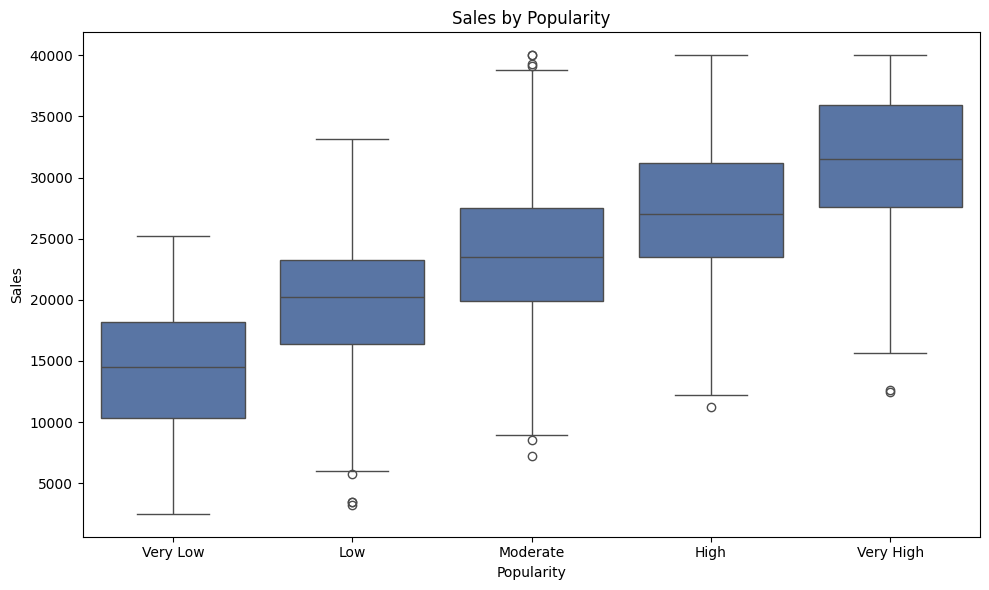

In [11]:
popularity_order = ["Very Low", "Low", "Moderate", "High", "Very High"]

plt.figure(figsize=(10, 6))
ax = sns.boxplot(data=df, x="Popularity", y="Sales", order=popularity_order, color="#4C72B0")
ax.set_title("Sales by Popularity")
ax.set_xlabel("Popularity")
ax.set_ylabel("Sales")
plt.tight_layout()
plt.show()

### Sales by Campaign Type

The box plot below shows Sales grouped by Campaign_Type to compare sales levels across campaign types.


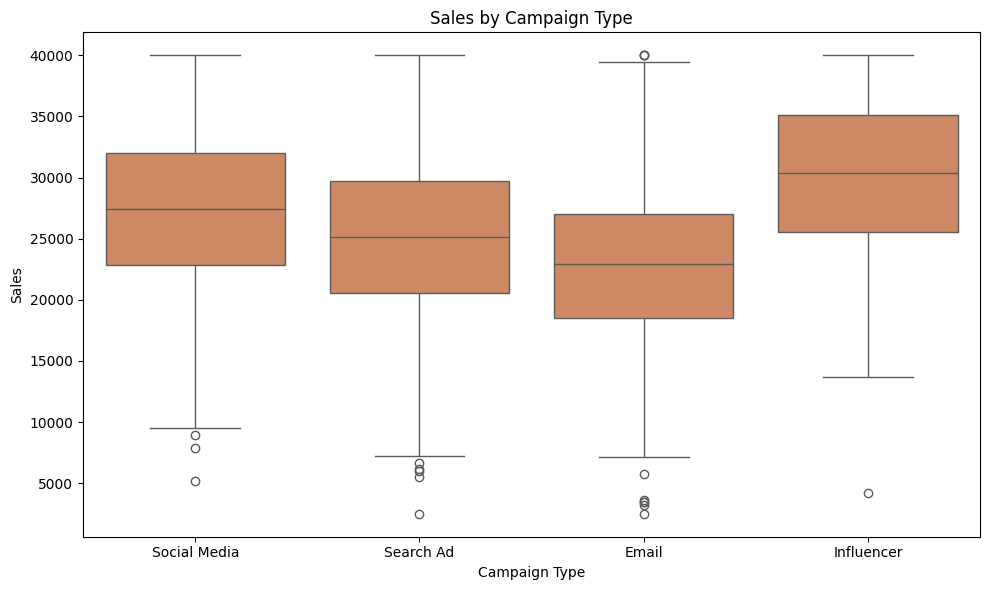

In [13]:
campaign_type_order = df["Campaign_Type"].value_counts().index.tolist()

plt.figure(figsize=(10, 6))
ax = sns.boxplot(data=df, x="Campaign_Type", y="Sales", order=campaign_type_order, color="#DD8452")
ax.set_title("Sales by Campaign Type")
ax.set_xlabel("Campaign Type")
ax.set_ylabel("Sales")
plt.tight_layout()
plt.show()

### Campaign Engagement Score vs Sales

The scatter plot below shows the raw relationship between Campaign_Engagement_Score and Sales.

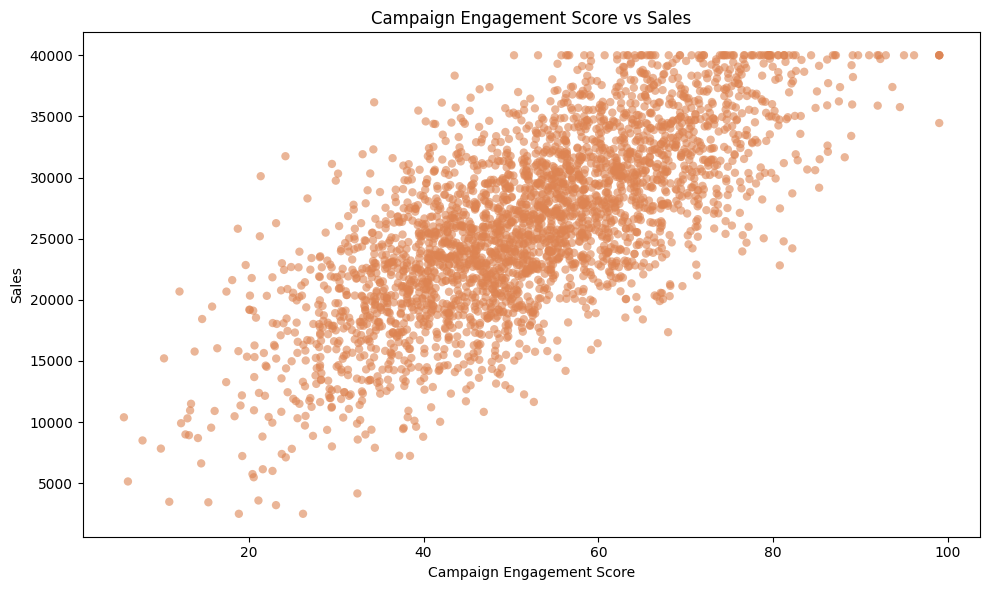

In [15]:
plt.figure(figsize=(10, 6))
plt.scatter(df["Campaign_Engagement_Score"], df["Sales"], alpha=0.6, color="#DD8452", edgecolors="none")
plt.title("Campaign Engagement Score vs Sales")
plt.xlabel("Campaign Engagement Score")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

### Discount Percentage vs Sales

The scatter plot below shows the raw relationship between Discount_Percentage and Sales.


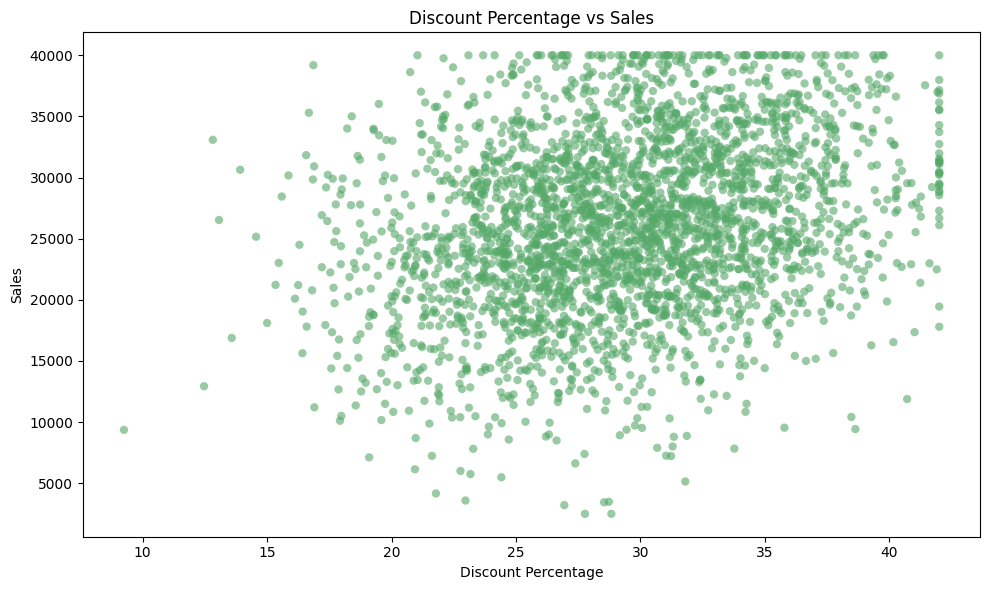

In [17]:
plt.figure(figsize=(10, 6))
plt.scatter(df["Discount_Percentage"], df["Sales"], alpha=0.6, color="#55A868", edgecolors="none")
plt.title("Discount Percentage vs Sales")
plt.xlabel("Discount Percentage")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

## Findings

Document your main bivariate insights here.